# EDA – Riesgo de adiciones en contratos SECOP II (muestra Salud)
**Contexto:** la tabla `SECOP II – Contratos Electrónicos` (jbjy-vk9h) quedó truncada en origen
(devuelve 1.000 filas desde el 24-oct-2026). Este EDA se hace con la descarga previa del sector Salud
(`src/ingest.py`, 800.011 contratos firmados desde 2017) y sigue la tabla de 9 revisiones del reporte.

**Entradas.** El mismo cuaderno se ejecuta con dos entradas, según las variables de entorno `EDA_TAG` y `EDA_INPUT`:
`salud` (descarga previa, 800 mil contratos; por defecto) y `snapshot` (instantánea de 1.000 filas de la tabla tal como
está hoy, todos los sectores). Con la instantánea, los umbrales de tamaño mínimo se reducen y los resultados son solo indicativos.

**Objetivo `y`** = 1 si el contrato registró adición en **valor** (tabla Adiciones, tipo "Adicion en el valor")
**o** en **tiempo** (`dias_adicionados > 0`).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import os
from pathlib import Path
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold

ROOT = Path("..")
TAG = os.environ.get("EDA_TAG", "salud")
INPUT = os.environ.get("EDA_INPUT", "contratos_salud.csv")
RAW, FIG = ROOT / "data/raw", ROOT / "reports" / ("figures" if TAG == "salud" else f"figures_{TAG}")
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.3f}".format
num = lambda s: pd.to_numeric(s, errors="coerce")

c = pd.read_csv(RAW / INPUT, low_memory=False)
a = pd.read_csv(RAW / "adiciones_valor.csv")
SMALL = len(c) < 50_000   # con muestras pequeñas se bajan los umbrales mínimos de tamaño
MIN_DEP, MIN_ENT, N_DEC = (15, 5, 5) if SMALL else (500, 200, 10)
print(TAG, INPUT, c.shape, a.shape, "| muestra pequeña:", SMALL)

salud contratos_salud.csv (800011, 45) (257152, 4) | muestra pequeña: False


## 0. Construcción de la variable objetivo y variables al momento de la firma

In [2]:
c["fecha_firma"] = pd.to_datetime(c.fecha_de_firma, errors="coerce")
c["anio"], c["mes"] = c.fecha_firma.dt.year.astype("Int64"), c.fecha_firma.dt.month.astype("Int64")
c["valor"] = num(c.valor_del_contrato)
dur = c.duraci_n_del_contrato.str.extract(r"(\d+)\s*([A-Za-z])")
mult = {"D": 1, "M": 30, "A": 365, "S": 7, "H": 1 / 24}
c["plazo_dias"] = num(dur[0]) * dur[1].map(mult)
c["saldo_cdp_n"] = num(c.saldo_cdp)

n_adic = a.groupby("id_contrato").size()
c["n_adic_valor"] = c.id_contrato.map(n_adic).fillna(0).astype(int)
c["dias_adic"] = num(c.dias_adicionados).fillna(0)
c["y_valor"] = (c.n_adic_valor > 0).astype(int)
c["y_tiempo"] = (c.dias_adic > 0).astype(int)
c["y"] = (c.y_valor | c.y_tiempo).astype(int)

print("Contratos sin fecha de firma válida:", c.fecha_firma.isna().sum())
print("dias_adicionados > 5 años (posible error de digitación):", (c.dias_adic > 1825).sum())

Contratos sin fecha de firma válida: 0
dias_adicionados > 5 años (posible error de digitación): 14


## 1. Tasa global de adición (balance de clases) y madurez de la muestra

Contratos 2017-2025: 667,817 | tasa y=27.1% | valor=7.1% | tiempo=22.0%
      contratos     y  valor  tiempo
anio                                
2017       1287 0.040  0.038   0.002
2018      23990 0.281  0.279   0.002
2019      24736 0.358  0.291   0.185
2020      56372 0.427  0.123   0.355
2021      67283 0.248  0.039   0.221
2022      85226 0.209  0.049   0.167
2023     116110 0.203  0.078   0.141
2024     136210 0.254  0.032   0.227
2025     156603 0.312  0.042   0.293


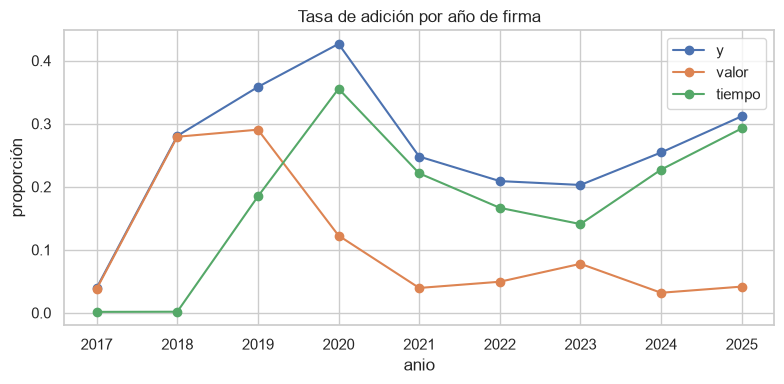

In [3]:
df = c[c.anio.between(2017, 2025)].copy()   # 2026 se excluye: contratos aún sin tiempo de recibir adiciones
print(f"Contratos 2017-2025: {len(df):,} | tasa y={df.y.mean():.1%} | valor={df.y_valor.mean():.1%} | tiempo={df.y_tiempo.mean():.1%}")
by_year = df.groupby("anio").agg(contratos=("y", "size"), y=("y", "mean"), valor=("y_valor", "mean"), tiempo=("y_tiempo", "mean"))
print(by_year.to_string())
ax = by_year[["y", "valor", "tiempo"]].plot(marker="o", figsize=(8, 4), title="Tasa de adición por año de firma")
ax.set_ylabel("proporción"); plt.tight_layout(); plt.savefig(FIG / "01_tasa_por_anio.png", dpi=150); plt.show()

In [4]:
by_state = df.groupby("estado_contrato").agg(contratos=("y", "size"), y=("y", "mean")).sort_values("contratos", ascending=False)
print(by_state.to_string())
print("El estado depende del desenlace ('Modificado' ya implica modificación): no debe usarse para definir la muestra ni como variable.")

                   contratos     y
estado_contrato                   
Modificado            230904 0.693
En ejecución          182494 0.006
Cerrado               119130 0.079
terminado             108639 0.093
Aprobado               24015 0.019
cedido                  1842 0.030
Suspendido               787 0.210
enviado Proveedor          3 0.000
En aprobación              2 0.000
Prorrogado                 1 1.000
El estado depende del desenlace ('Modificado' ya implica modificación): no debe usarse para definir la muestra ni como variable.


## 2. Nulos / valores no definidos en variables de firma

valor                           0.000
modalidad_de_contratacion       0.000
origen_de_los_recursos          0.000
es_pyme                         0.000
codigo_proveedor                0.000
saldo_cdp_n                     0.000
tipo_de_contrato                0.000
justificacion_modalidad_de      0.000
tipodocproveedor                0.100
fecha_de_inicio_del_contrato    1.200
departamento                    3.300
plazo_dias                     11.800
habilita_pago_adelantado       12.700
condiciones_de_entrega         22.600


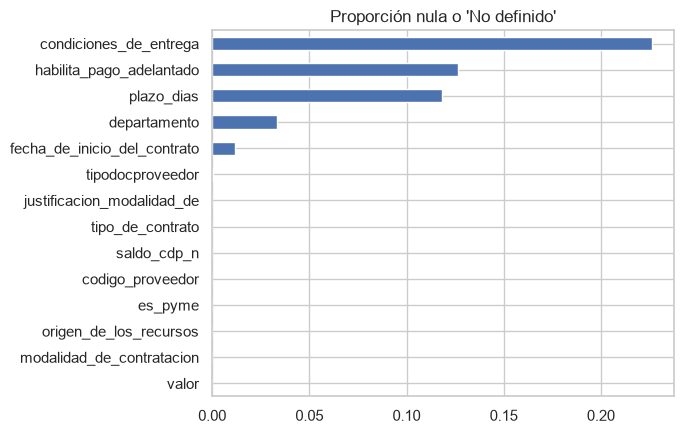

Ofertas, garantías y proveedores (tablas aparte) no se descargaron en esta muestra: ver limitaciones.


In [5]:
firma_vars = ["valor", "plazo_dias", "modalidad_de_contratacion", "tipo_de_contrato", "departamento", "origen_de_los_recursos",
              "condiciones_de_entrega", "tipodocproveedor", "es_pyme", "habilita_pago_adelantado", "codigo_proveedor",
              "fecha_de_inicio_del_contrato", "saldo_cdp_n", "justificacion_modalidad_de"]
undef = lambda s: s.isna() | s.astype(str).str.strip().str.lower().isin(["no definido", "no definida", "sin descripcion", "nan", "no d"])
nul = pd.Series({v: undef(df[v]).mean() for v in firma_vars}).sort_values()
print((nul * 100).round(1).to_string())
nul.plot.barh(figsize=(7, 4.5), title="Proporción nula o 'No definido'"); plt.tight_layout(); plt.savefig(FIG / "02_nulos.png", dpi=150); plt.show()
print("Ofertas, garantías y proveedores (tablas aparte) no se descargaron en esta muestra: ver limitaciones.")

## 3. Variación por departamento

                                          contratos     y
departamento                                             
Bolívar                                       16212 0.250
Caquetá                                        1576 0.251
Boyacá                                         8132 0.261
Cundinamarca                                  27119 0.287
Guainía                                         582 0.318
Quindío                                        4520 0.340
San Andrés, Providencia y Santa Catalina        661 0.378
Distrito Capital de Bogotá                   297513 0.403
                    contratos     y
departamento                       
Chocó                    4223 0.094
Cesar                    5580 0.105
No Definido             22138 0.109
Norte de Santander      19203 0.112
Nariño                  11391 0.114
Rango de tasa entre departamentos (n>=500): 9.4% - 40.3%


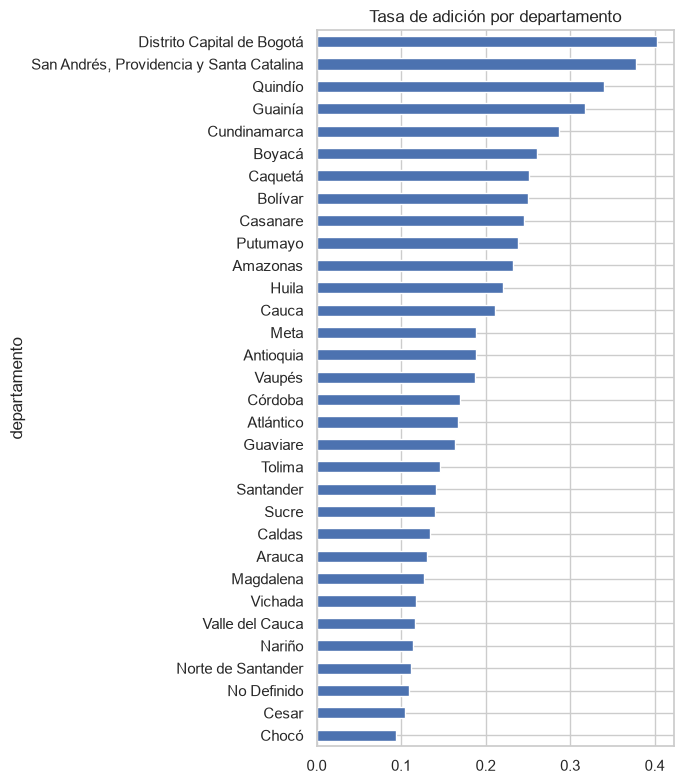

In [6]:
dep = df.groupby("departamento").agg(contratos=("y", "size"), y=("y", "mean")).query("contratos >= @MIN_DEP").sort_values("y")
print(dep.tail(8).to_string()); print(dep.head(5).to_string())
print(f"Rango de tasa entre departamentos (n>={MIN_DEP}): {dep.y.min():.1%} - {dep.y.max():.1%}")
dep.y.plot.barh(figsize=(7, 8), title="Tasa de adición por departamento"); plt.tight_layout(); plt.savefig(FIG / "03_departamento.png", dpi=150); plt.show()

## 4. Modalidad de contratación y tipo de contrato

                                                             contratos     y  valor  tiempo
modalidad_de_contratacion                                                                  
Contratación régimen especial                                   445735 0.314  0.090   0.252
Contratación directa                                            192486 0.181  0.027   0.157
Mínima cuantía                                                   10972 0.174  0.095   0.086
Contratación régimen especial (con ofertas)                       7933 0.291  0.061   0.241
Contratación Directa (con ofertas)                                6089 0.147  0.054   0.100
Selección Abreviada de Menor Cuantía                              2139 0.332  0.179   0.176
Selección abreviada subasta inversa                               1791 0.178  0.068   0.118
Licitación pública                                                 343 0.411  0.184   0.259
Concurso de méritos abierto                                        243 0.300  0.

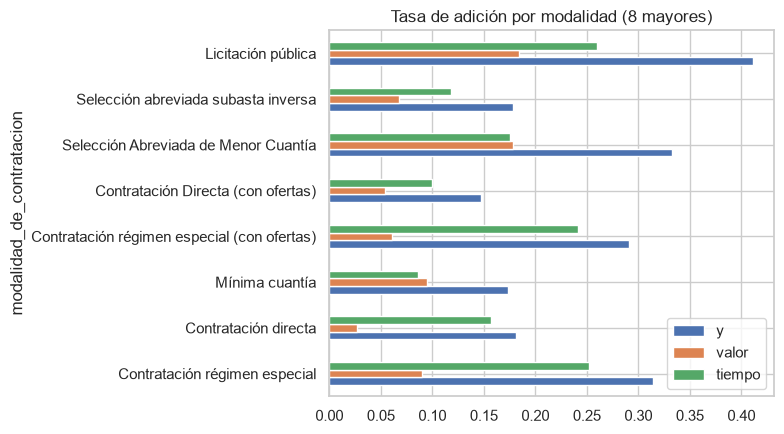

In [7]:
mod = df.groupby("modalidad_de_contratacion").agg(contratos=("y", "size"), y=("y", "mean"), valor=("y_valor", "mean"), tiempo=("y_tiempo", "mean")).sort_values("contratos", ascending=False)
print(mod.to_string())
print("Categorías con < 1.000 contratos:", (mod.contratos < 1000).sum(), "de", len(mod))
tip = df.groupby("tipo_de_contrato").agg(contratos=("y", "size"), y=("y", "mean")).sort_values("contratos", ascending=False).head(10)
print(tip.to_string())
mod.head(8)[["y", "valor", "tiempo"]].plot.barh(figsize=(8, 4.5), title="Tasa de adición por modalidad (8 mayores)")
plt.tight_layout(); plt.savefig(FIG / "04_modalidad.png", dpi=150); plt.show()

## 5. Valor y plazo vs adición

dec_valor
1    0.046
2    0.115
3    0.205
4    0.228
5    0.283
6    0.301
7    0.340
8    0.357
9    0.373
10   0.323


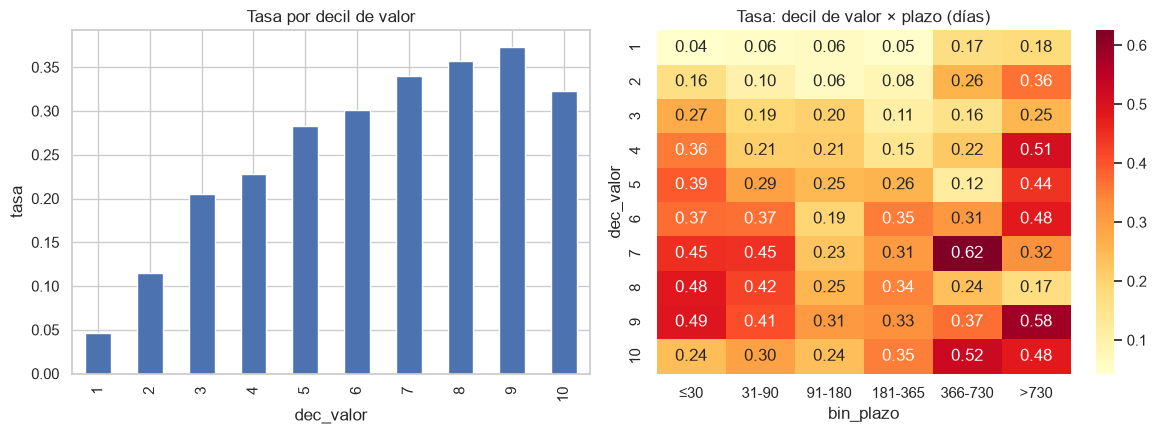

Spearman valor~y: 0.217 | plazo~y: 0.049


In [8]:
d5 = df[(df.valor > 0) & (df.plazo_dias > 0) & (df.plazo_dias <= 3650)].copy()
d5["dec_valor"] = pd.qcut(d5.valor, N_DEC, labels=False, duplicates="drop") + 1
d5["bin_plazo"] = pd.cut(d5.plazo_dias, [0, 30, 90, 180, 365, 730, 3650], labels=["≤30", "31-90", "91-180", "181-365", "366-730", ">730"])
rate_v = d5.groupby("dec_valor").y.mean()
print(rate_v.round(3).to_string())
hm = d5.pivot_table(index="dec_valor", columns="bin_plazo", values="y", aggfunc="mean", observed=True)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
rate_v.plot.bar(ax=ax[0], title="Tasa por decil de valor"); ax[0].set_ylabel("tasa")
sns.heatmap(hm, annot=True, fmt=".2f", cmap="YlOrRd", ax=ax[1]); ax[1].set_title("Tasa: decil de valor × plazo (días)")
plt.tight_layout(); plt.savefig(FIG / "05_valor_plazo.png", dpi=150); plt.show()
print("Spearman valor~y:", round(d5[["valor", "y"]].corr("spearman").iloc[0, 1], 3), "| plazo~y:", round(d5[["plazo_dias", "y"]].corr("spearman").iloc[0, 1], 3))

## 6. Estacionalidad (mes de firma)

mes                1          2          3          4          5          6          7          8          9          10         11         12
contratos 122,649.000 92,309.000 52,310.000 35,504.000 38,999.000 35,530.000 47,685.000 44,507.000 48,331.000 54,510.000 45,692.000 49,791.000
y               0.331      0.324      0.328      0.269      0.268      0.213      0.201      0.223      0.285      0.260      0.152      0.231


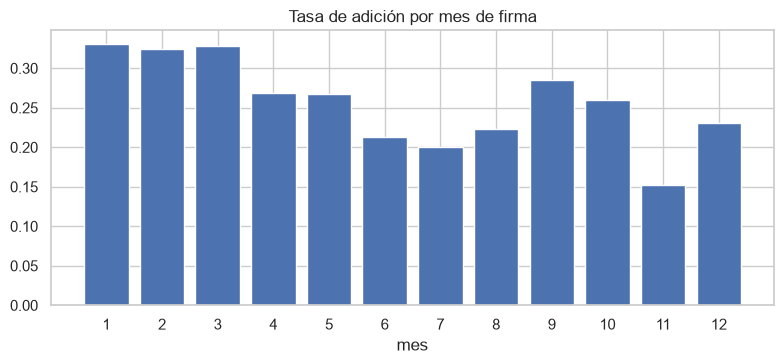

Mes con mayor/menor tasa: 1 (33.1%) / 11 (15.2%)


In [9]:
mes = df.groupby("mes").agg(contratos=("y", "size"), y=("y", "mean"))
print(mes.T.to_string())
fig, ax = plt.subplots(figsize=(8, 3.8)); ax.bar(mes.index, mes.y); ax.set_xticks(range(1, 13)); ax.set_title("Tasa de adición por mes de firma"); ax.set_xlabel("mes")
plt.tight_layout(); plt.savefig(FIG / "06_mes.png", dpi=150); plt.show()
print(f"Mes con mayor/menor tasa: {mes.y.idxmax()} ({mes.y.max():.1%}) / {mes.y.idxmin()} ({mes.y.min():.1%})")

## 7. Concentración por entidad

Entidades: 633. Top 10 concentran 66.4% de los contratos con adición; top 100: 95.3%
                                                                             contratos   adic     y
nombre_entidad                                                                                     
SUBRED INTEGRADA DE SERVICIO DE SALUD CENTRO ORIENTE E.S.E 1                     46872  31523 0.673
SUBRED INTEGRADA DE SERVICIOS DE SALUD SUR OCCIDENTE ESE.                        59448  25731 0.433
SUBRED INTEGRADA DE SERVICIOS DE SALUD SUR E.S.E.**                              51882  22687 0.437
SUBRED INTEGRADA DE SERVICIOS DE SALUD NORTE E.S.E. (OFICIAL)                    50491  21339 0.423
INSTITUTO DISTRITAL PARA LA PROTECCIÓN DE LA NIÑEZ Y LA JUVENTUD - IDIPRON*      17867   7585 0.425
ESE HOSPITAL UNIVERSITARIO JULIO MENDEZ BARRENECHE                               18359   3031 0.165
ICBF REGIONAL BOGOTA                                                             10148   2214 0.218
ICBF REGIONAL V

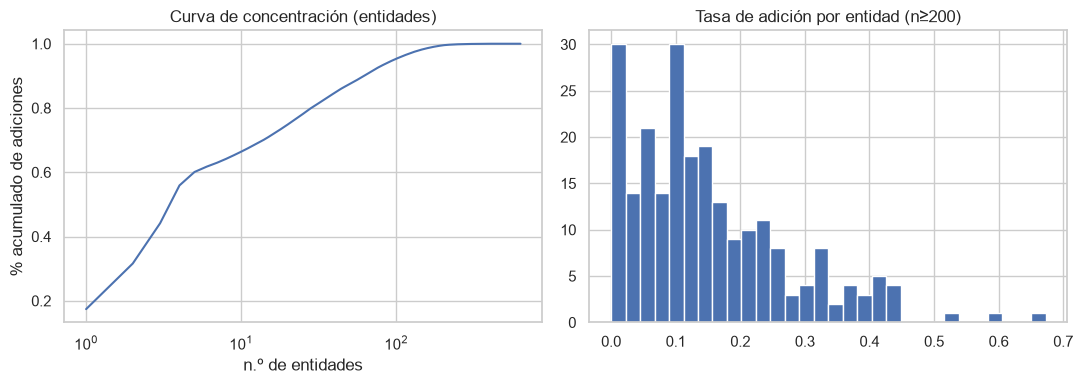

In [10]:
ent = df.groupby("nombre_entidad").agg(contratos=("y", "size"), adic=("y", "sum"), y=("y", "mean")).sort_values("adic", ascending=False)
ent["acum"] = ent.adic.cumsum() / ent.adic.sum()
print(f"Entidades: {len(ent):,}. Top 10 concentran {ent.acum.iloc[min(9, len(ent) - 1)]:.1%} de los contratos con adición; top 100: {ent.acum.iloc[min(99, len(ent) - 1)]:.1%}")
print(ent.head(10)[["contratos", "adic", "y"]].to_string())
big = ent[ent.contratos >= MIN_ENT]
print(f"Entidades con >={MIN_ENT} contratos: {len(big)}. Tasa p10/p50/p90: {big.y.quantile([.1, .5, .9]).round(3).tolist()}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(range(1, len(ent) + 1), ent.acum.values); ax[0].set_xscale("log"); ax[0].set_title("Curva de concentración (entidades)")
ax[0].set_xlabel("n.º de entidades"); ax[0].set_ylabel("% acumulado de adiciones")
if len(big): big.y.hist(bins=30, ax=ax[1])
ax[1].set_title(f"Tasa de adición por entidad (n≥{MIN_ENT})")
plt.tight_layout(); plt.savefig(FIG / "07_entidades.png", dpi=150); plt.show()

## 8. Adición en tiempo vs en valor

In [11]:
print(pd.crosstab(df.y_valor, df.y_tiempo, margins=True).to_string())
print("P(valor | tiempo) =", round(df[df.y_tiempo == 1].y_valor.mean(), 3), "| P(tiempo | valor) =", round(df[df.y_valor == 1].y_tiempo.mean(), 3))
pm = df[df.modalidad_de_contratacion.isin(mod.head(6).index)].groupby("modalidad_de_contratacion")[["y_valor", "y_tiempo"]].mean()
print(pm.round(3).to_string())
print(df.groupby("tipo_de_contrato")[["y_valor", "y_tiempo"]].mean().loc[tip.index[:6]].round(3).to_string())

y_tiempo       0       1     All
y_valor                         
0         486617  133608  620225
1          34375   13217   47592
All       520992  146825  667817
P(valor | tiempo) = 0.09 | P(tiempo | valor) = 0.278


                                             y_valor  y_tiempo
modalidad_de_contratacion                                     
Contratación Directa (con ofertas)             0.054     0.100
Contratación directa                           0.027     0.157
Contratación régimen especial                  0.090     0.252
Contratación régimen especial (con ofertas)    0.061     0.241
Mínima cuantía                                 0.095     0.086
Selección Abreviada de Menor Cuantía           0.179     0.176
                         y_valor  y_tiempo
tipo_de_contrato                          
Prestación de servicios    0.072     0.248
Decreto 092 de 2017        0.049     0.133
Otro                       0.122     0.165
Suministros                0.075     0.105
Compraventa                0.017     0.062
Comodato                   0.000     0.128


## 9. Fuga de información: poder predictivo de una sola variable (AUC)
AUC univariada contra `y`. Numéricas: AUC directa. Categóricas: codificación por la tasa del *fold* de entrenamiento (5-fold).
Valores cercanos a 1 = sospecha de fuga; ~0,5 = sin señal.

                 variable                            momento  auc_univariada
                dias_adic  SOSPECHOSA (posterior a la firma)           0.905
          estado_contrato SOSPECHOSA (depende del desenlace)           0.891
           nombre_entidad                              firma           0.761
             departamento                              firma           0.672
                    valor                              firma           0.644
   condiciones_de_entrega                              firma           0.598
modalidad_de_contratacion                              firma           0.573
                      mes                              firma           0.564
         tipo_de_contrato                              firma           0.551
               plazo_dias                              firma           0.532
                    orden                              firma           0.530
            ultima_act_ts  SOSPECHOSA (posterior a la firma)           0.529

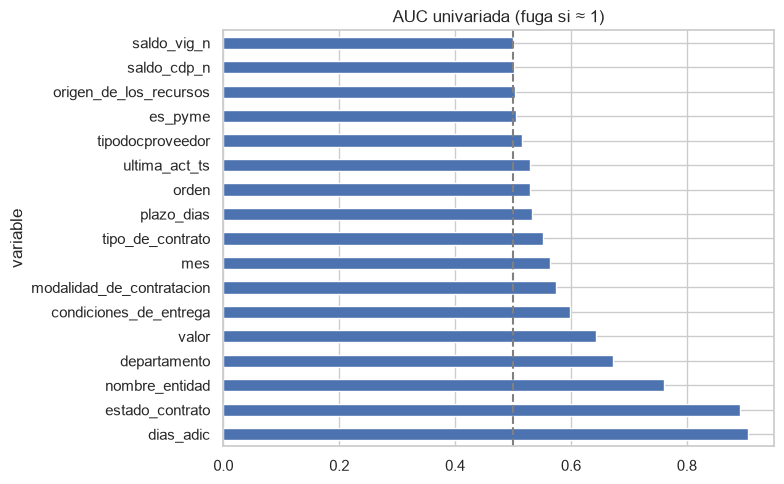

In [12]:
def auc_num(x, y):
    m = x.notna(); s = roc_auc_score(y[m], x[m]); return max(s, 1 - s)

def auc_cat(x, y, k=5):
    x = x.fillna("NA").astype(str).reset_index(drop=True); y = y.reset_index(drop=True); oof = np.zeros(len(x))
    for tr, te in KFold(k, shuffle=True, random_state=0).split(x):
        rate = y.iloc[tr].groupby(x.iloc[tr]).mean()
        oof[te] = x.iloc[te].map(rate).fillna(y.iloc[tr].mean()).values
    return roc_auc_score(y, oof)

df["ultima_act_ts"] = pd.to_datetime(df.ultima_actualizacion, errors="coerce").astype("int64") / 1e9
df.loc[df.ultima_actualizacion.isna(), "ultima_act_ts"] = np.nan
df["saldo_vig_n"] = num(df.saldo_vigencia)
res = []
for v in ["valor", "plazo_dias", "saldo_cdp_n", "mes"]:
    res.append((v, "firma", auc_num(df[v], df.y)))
for v in ["modalidad_de_contratacion", "tipo_de_contrato", "departamento", "nombre_entidad", "origen_de_los_recursos",
          "condiciones_de_entrega", "tipodocproveedor", "es_pyme", "orden"]:
    res.append((v, "firma", auc_cat(df[v], df.y)))
for v in ["saldo_vig_n", "ultima_act_ts", "dias_adic"]:
    res.append((v, "SOSPECHOSA (posterior a la firma)", auc_num(df[v], df.y)))
res.append(("estado_contrato", "SOSPECHOSA (depende del desenlace)", auc_cat(df.estado_contrato, df.y)))
leak = pd.DataFrame(res, columns=["variable", "momento", "auc_univariada"]).sort_values("auc_univariada", ascending=False)
print(leak.round(3).to_string(index=False))
leak.set_index("variable").auc_univariada.plot.barh(figsize=(8, 5), title="AUC univariada (fuga si ≈ 1)"); plt.axvline(0.5, color="gray", ls="--")
plt.tight_layout(); plt.savefig(FIG / "09_fuga_auc.png", dpi=150); plt.show()

In [13]:
print("Valor mediano del contrato según tenga o no adición en valor:")
print(df.groupby("y_valor").valor.median().to_string())

Valor mediano del contrato según tenga o no adición en valor:
y_valor
0   16,492,056.000
1   27,110,510.000
